In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.1.3


In [2]:
import sys
import sklearn

print("Python version:", sys.version)
print("Scikit-learn:", sklearn.__version__)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1


In [3]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicated rows:", df.duplicated().sum())

Missing values per column:
Series([], dtype: int64)

Total missing values:
0

Duplicated rows: 0


In [8]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [9]:
print(df["Churn"].value_counts())

print("\nTarget distribution (%):")
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target distribution (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [10]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Series([], dtype: int64)

Total missing values:
0

Duplicate rows:
0


In [11]:
print(df["TotalCharges"].head(10).tolist())

print("\nData type:")
print(df["TotalCharges"].dtype)

total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("\nValues that could not be converted:")
print(total_charges_numeric.isna().sum())

['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']

Data type:
object

Values that could not be converted:
11


In [12]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


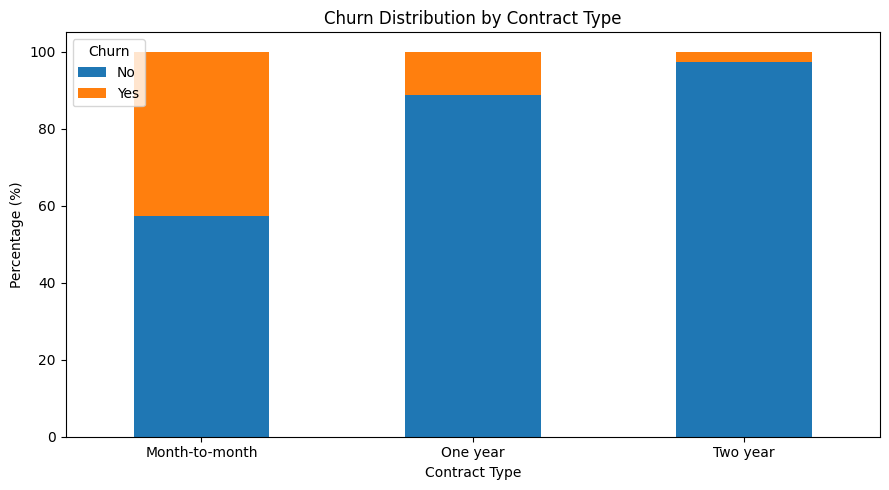

In [13]:
churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

invalid_mask = total_charges_numeric.isna()

print("Invalid TotalCharges values:")
print(df.loc[invalid_mask, ["customerID", "tenure", "TotalCharges", "Churn"]])

print("\nTenure distribution of invalid rows:")
print(df.loc[invalid_mask, "tenure"].value_counts())

Invalid TotalCharges values:
      customerID  tenure TotalCharges Churn
488   4472-LVYGI       0                 No
753   3115-CZMZD       0                 No
936   5709-LVOEQ       0                 No
1082  4367-NUYAO       0                 No
1340  1371-DWPAZ       0                 No
3331  7644-OMVMY       0                 No
3826  3213-VVOLG       0                 No
4380  2520-SGTTA       0                 No
5218  2923-ARZLG       0                 No
6670  4075-WKNIU       0                 No
6754  2775-SEFEE       0                 No

Tenure distribution of invalid rows:
tenure
0    11
Name: count, dtype: int64


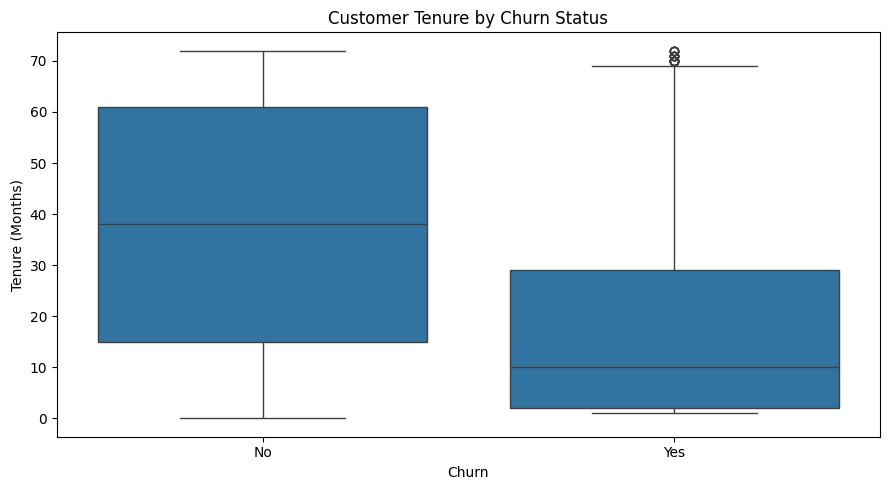

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

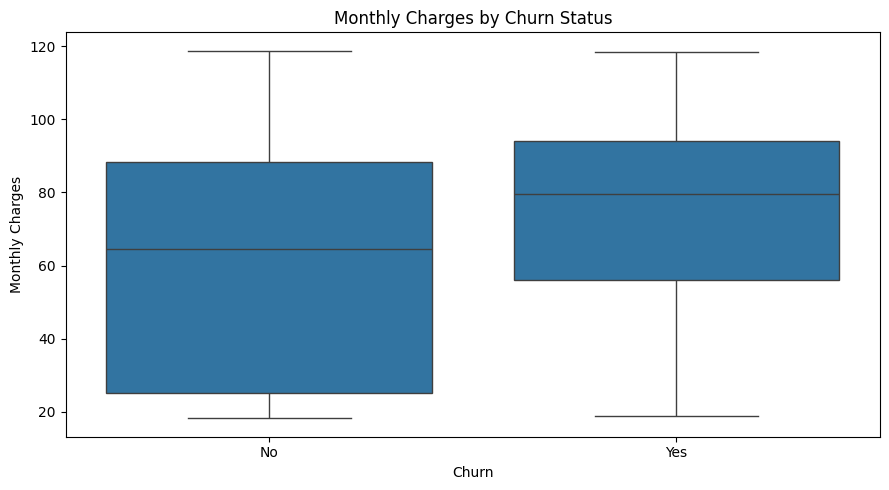

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [17]:
categorical_features = [
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod"
]

for col in categorical_features:
    churn_rate = (
        df.groupby(col, observed=False)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {col}:")
    print(churn_rate.round(2))


Churn rate by InternetService:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn rate by OnlineSecurity:
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

Churn rate by TechSupport:
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64

Churn rate by PaymentMethod:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


In [18]:
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

mask = (
    df_clean["TotalCharges"].isna()
    & (df_clean["tenure"] == 0)
)

df_clean.loc[mask, "TotalCharges"] = 0

print("Missing values after cleaning:")
print(df_clean.isna().sum().sort_values(ascending=False).head())

print("\nTotalCharges data type:")
print(df_clean["TotalCharges"].dtype)

print("\nNumber of invalid TotalCharges values remaining:")
print(df_clean["TotalCharges"].isna().sum())

Missing values after cleaning:
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

TotalCharges data type:
float64

Number of invalid TotalCharges values remaining:
0


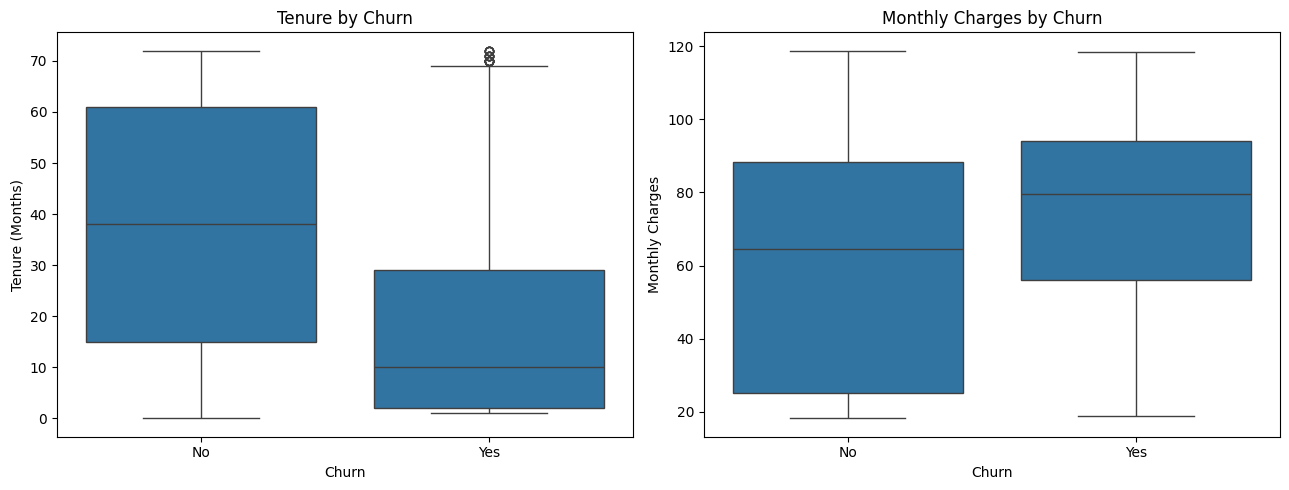

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    ax=axes[0]
)
axes[0].set_title("Tenure by Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (Months)")

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [20]:
print("Total missing values:", df_clean.isna().sum().sum())

print("Dataset shape:", df_clean.shape)

print("\nTarget distribution:")
print(df_clean["Churn"].value_counts(normalize=True).mul(100).round(2))

print("\nData types:")
print(df_clean.dtypes)

Total missing values: 0
Dataset shape: (7043, 21)

Target distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [21]:
X = df_clean.drop(columns=["Churn", "customerID"])

y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nChurn rate in training set:")
print(y_train.mean().round(3))

print("\nChurn rate in test set:")
print(y_test.mean().round(3))

Training set: (5634, 19)
Test set: (1409, 19)

Churn rate in training set:
0.265

Churn rate in test set:
0.265


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [24]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [25]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_pred), 4))

print("Baseline Precision:",
      round(precision_score(
          y_test, baseline_pred, zero_division=0
      ), 4))

print("Baseline Recall:",
      round(recall_score(y_test, baseline_pred), 4))

print("Baseline F1-score:",
      round(f1_score(y_test, baseline_pred), 4))

Baseline Accuracy: 0.7346
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred), 4))

print("Random Forest Precision:",
      round(precision_score(y_test, rf_pred), 4))

print("Random Forest Recall:",
      round(recall_score(y_test, rf_pred), 4))

print("Random Forest F1-score:",
      round(f1_score(y_test, rf_pred), 4))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_proba), 4))

Random Forest Accuracy: 0.7977
Random Forest Precision: 0.6551
Random Forest Recall: 0.5027
Random Forest F1-score: 0.5688
Random Forest ROC-AUC: 0.8337


In [29]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   object 
 1   SeniorCitizen     5634 non-null   int64  
 2   Partner           5634 non-null   object 
 3   Dependents        5634 non-null   object 
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   object 
 6   MultipleLines     5634 non-null   object 
 7   InternetService   5634 non-null   object 
 8   OnlineSecurity    5634 non-null   object 
 9   OnlineBackup      5634 non-null   object 
 10  DeviceProtection  5634 non-null   object 
 11  TechSupport       5634 non-null   object 
 12  StreamingTV       5634 non-null   object 
 13  StreamingMovies   5634 non-null   object 
 14  Contract          5634 non-null   object 
 15  PaperlessBilling  5634 non-null   object 
 16  PaymentMethod     5634 non-null   object 
 1

In [30]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

y_proba_lr = model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_pred_threshold = (
        y_proba_lr >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test, y_pred_threshold
        ),
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(
    threshold_results.round(3).to_string(index=False)
)

 Threshold  Accuracy  Precision  Recall  F1-score
      0.20     0.703      0.467   0.856     0.604
      0.25     0.732      0.498   0.810     0.616
      0.30     0.749      0.519   0.754     0.615
      0.35     0.764      0.543   0.706     0.614
      0.40     0.777      0.568   0.668     0.614
      0.45     0.790      0.602   0.615     0.608
      0.50     0.806      0.657   0.559     0.604


In [31]:
# Access the fitted preprocessing step
fitted_preprocessor = model.named_steps["preprocessor"]

# Transform a few test rows
X_test_transformed = fitted_preprocessor.transform(
    X_test.head()
)

print("Original feature count:", X_test.shape[1])
print("Transformed feature count:", X_test_transformed.shape[1])
print("Transformed data type:", type(X_test_transformed))

Original feature count: 19
Transformed feature count: 45
Transformed data type: <class 'numpy.ndarray'>


In [32]:
feature_names = fitted_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 30 transformed feature names:")
print(feature_names[:30])

Number of transformed features: 45

First 30 transformed feature names:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__DeviceProtection_Yes' 'cat__TechSupport_No'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes']


In [33]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test.shape)

print("\nChurn rate:")
print("Training:", round(y_train_new.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Test:", round(y_test.mean(), 3))

Training set: (4225, 19)
Validation set: (1409, 19)
Final test set: (1409, 19)

Churn rate:
Training: 0.265
Validation: 0.265
Test: 0.265


In [34]:
print("Raw training data:", X_train_new.shape)

print(
    "Transformed training data:",
    model.named_steps["preprocessor"]
    .transform(X_train_new).shape
)

print("Raw validation data:", X_val.shape)

print(
    "Transformed validation data:",
    model.named_steps["preprocessor"]
    .transform(X_val).shape
)

Raw training data: (4225, 19)
Transformed training data: (4225, 45)
Raw validation data: (1409, 19)
Transformed validation data: (1409, 45)


In [35]:

y_val_proba = model.predict_proba(X_val)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

validation_results = pd.DataFrame(results)

print(validation_results.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.20      0.465   0.848     0.601
      0.25      0.506   0.802     0.620
      0.30      0.534   0.751     0.624
      0.35      0.573   0.703     0.631
      0.40      0.600   0.658     0.628
      0.45      0.627   0.594     0.610
      0.50      0.668   0.543     0.599


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

selected_threshold = 0.35

y_test_proba = model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, y_test_pred), 4
))
print("Precision:", round(
    precision_score(y_test, y_test_pred), 4
))
print("Recall:", round(
    recall_score(y_test, y_test_pred), 4
))
print("F1-score:", round(
    f1_score(y_test, y_test_pred), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_proba), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Selected threshold: 0.35
Accuracy: 0.7644
Precision: 0.5432
Recall: 0.7059
F1-score: 0.614
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

Confusion Matrix:
[[813 222]
 [110 264]]


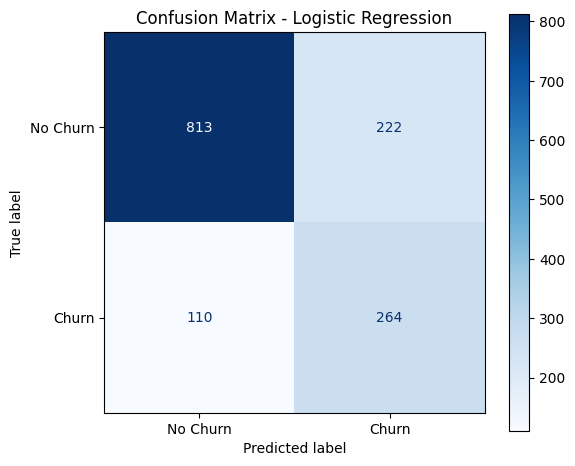

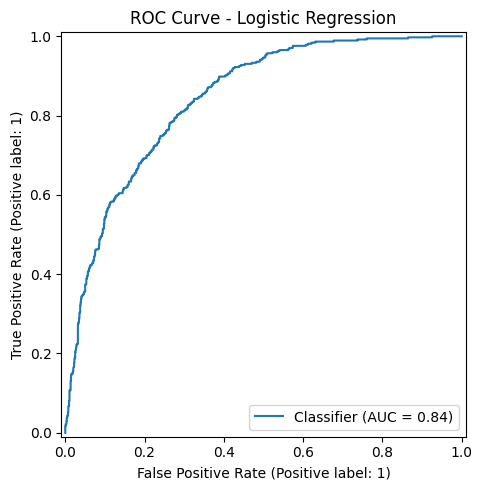

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


# 2. ROC Curve
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    ax=ax
)

ax.set_title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()

In [39]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

coefficients = model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values(
    "abs_coefficient",
    ascending=False
)

display(coef_df.head(15))


,feature,coefficient,abs_coefficient
1,num__tenure,-1.257539,1.257539
38,cat__Contract_Two year,-0.776594,0.776594
15,cat__InternetService_DSL,-0.648646,0.648646
16,cat__InternetService_Fiber optic,0.634195,0.634195
2,num__MonthlyCharges,-0.591863,0.591863
36,cat__Contract_Month-to-month,0.582883,0.582883
3,num__TotalCharges,0.536253,0.536253
39,cat__PaperlessBilling_No,-0.343227,0.343227
25,cat__DeviceProtection_No internet service,-0.300104,0.300104
17,cat__InternetService_No,-0.300104,0.300104


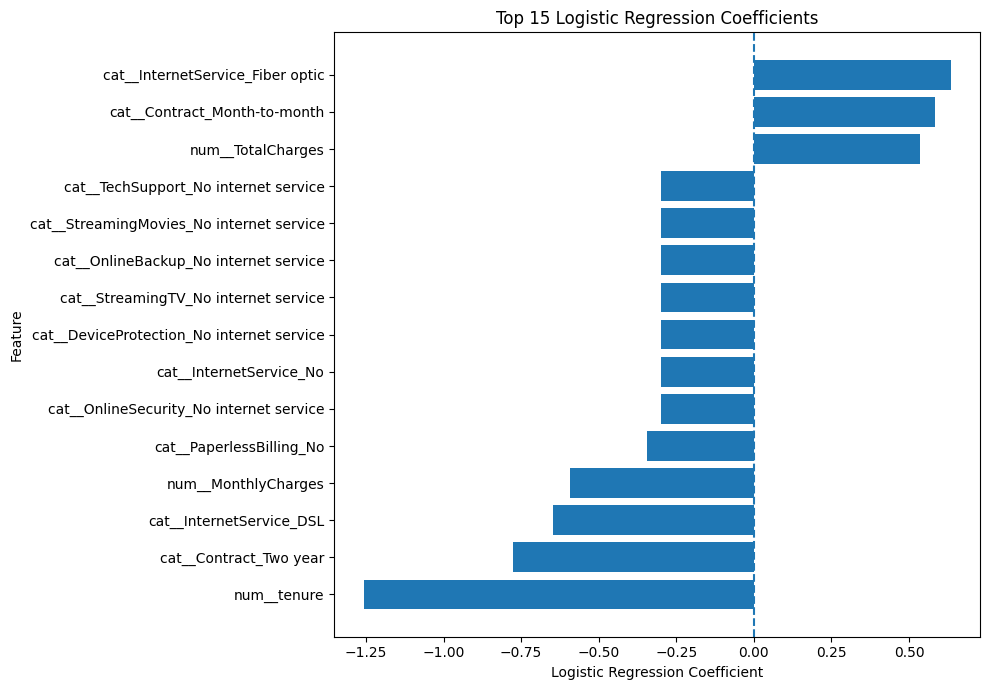

In [40]:
top_features = (
    coef_df.nlargest(15, "abs_coefficient")
    .sort_values("coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()


In [41]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    model_dir / "churn_pipeline.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [42]:
# For Next Load Model
#loaded_model = joblib.load("models/churn_pipeline.joblib")

# For next customer Predict
# predictions = loaded_model.predict(new_customer_data)

In [43]:
import joblib

model_bundle = {
    "model": model,
    "threshold": selected_threshold,
    "model_name": "Logistic Regression",
    "target": "Churn"
}

joblib.dump(
    model_bundle,
    "models/churn_model_bundle.joblib"
)

print("Model bundle saved successfully!")

Model bundle saved successfully!


In [44]:
## FOR GITHUB ##

In [45]:
from pathlib import Path

project_dir = Path("/content/customer-churn-prediction")

folders = [
    "data",
    "notebooks",
    "models",
    "src",
    "tests"
]

for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

for path in sorted(project_dir.rglob("*")):
    print(path.relative_to(project_dir))

Project folders created successfully!
data
models
notebooks
src
tests


In [46]:
import shutil

source = Path("/content/models/churn_model_bundle.joblib")
destination = project_dir / "models" / "churn_model_bundle.joblib"

shutil.copy2(source, destination)

print("Model copied:", destination.exists())

Model copied: True


In [47]:
gitignore_content = """
__pycache__/
*.py[cod]
.ipynb_checkpoints/

.venv/
venv/
.env

data/*.csv
data/*.xlsx

.DS_Store
"""

(project_dir / ".gitignore").write_text(
    gitignore_content.strip() + "\n"
)

print(".gitignore created!")

.gitignore created!


In [48]:
from pathlib import Path

notebook_files = list(
    Path("/content").rglob("01_customer_churn_eda.ipynb")
)

for file in notebook_files:
    print(file)